# Практическая работа 1. Одномерные массивы и графики

Цель работы — освоить представление числовых данных одномерными массивами, их формирование по правилу, визуализацию и простейший анализ.

Версия методички: **v6**.

В работе одна и та же зависимость последовательно рассматривается как набор чисел, как результат вычислений над массивом и как график. Новые конструкции вводятся непосредственно перед задачей, в которой они необходимы.

# План работы

1. Одномерные последовательности: индексы и срезы.
2. Генерация и обработка последовательностей.
3. NumPy-массивы и векторные вычисления.
4. Построение и способы отображения графиков.
5. Оформление и сравнение графиков.
6. Табличный, числовой и визуальный анализ.
7. Три семейства функций, особые точки и логарифмический масштаб.
8. Самостоятельная работа.
9. Контрольные задания.

# 1. Одномерные последовательности: индексы и срезы

Одномерная последовательность — исходная форма хранения упорядоченного набора чисел. На этом этапе важны не сами числа, а способ обращения к ним по позиции.

### Пример 1. Длина и индекс

**Задача.** Для списка `x = [4, 1, -2, 7, 0]` определить число элементов, первый элемент, элемент с индексом 2 и последний элемент.

**Понятия, уже использованные в работе:** —.

**Новые понятия:** `python_list`, `len`, `indexing`.

#### Новые понятия

- `python_list` — Одномерная изменяемая последовательность Python, заданная литералом [...].
- `len` — Определение числа элементов последовательности.
- `indexing` — Доступ к элементу последовательности по индексу; индексация Python начинается с 0.

#### Математическая модель

Для последовательности
$$x = [x_0,x_1,\ldots,x_{N-1}]$$
число элементов равно $N$, а допустимые неотрицательные индексы лежат в диапазоне от $0$ до $N-1$.

#### Числовой пример

Если
$$x=[4,1,-2,7,0],$$
то $N=5$, $x_0=4$, $x_2=-2$, $x_4=0$.

#### Объяснение

В Python список задаётся квадратными скобками. Индекс — номер позиции элемента, причём нумерация начинается с нуля. Это правило далее используется и для NumPy-массивов.

#### Код решения

In [1]:
x = [4, 1, -2, 7, 0]
print('len =', len(x))
print('x[0] =', x[0])
print('x[2] =', x[2])
print('last =', x[len(x) - 1])

len = 5
x[0] = 4
x[2] = -2
last = 0


#### Разбор кода

`x` хранит последовательность чисел. `len(x)` даёт количество элементов. Выражение `x[i]` выбирает элемент с индексом `i`; первый элемент имеет индекс 0. Последний индекс равен `len(x)-1`.

### Пример 2. Индексы с конца и срезы

**Задача.** Получить последний элемент, элементы с индексами от 2 до 5, каждый второй элемент и элементы в обратном порядке.

**Понятия, уже использованные в работе:** `python_list`, `len`, `indexing`.

**Новые понятия:** `negative_index`, `slice`.

#### Новые понятия

- `negative_index` — Доступ к элементам с конца последовательности с помощью отрицательных индексов.
- `slice` — Получение части последовательности записью start:stop:step; граница stop не включается.

#### Математическая модель

Срез задаётся тройкой
$$x[a:b:s],$$
где $a$ — начальный индекс, $b$ — граница, не входящая в результат, $s$ — шаг.

#### Числовой пример

Для $x=[0,1,2,3,4,5,6,7,8,9]$ срез `x[2:6]` даёт $[2,3,4,5]$, а `x[::2]` — $[0,2,4,6,8]$.

#### Объяснение

Отрицательные индексы удобны, когда важна позиция от конца: `-1` — последний элемент, `-2` — предпоследний. Срез позволяет получить сразу часть последовательности без явного цикла.

#### Код решения

In [2]:
x = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
print('last:', x[-1])
print('x[2:6]:', x[2:6])
print('x[::2]:', x[::2])
print('x[::-1]:', x[::-1])

last: 9
x[2:6]: [2, 3, 4, 5]
x[::2]: [0, 2, 4, 6, 8]
x[::-1]: [9, 8, 7, 6, 5, 4, 3, 2, 1, 0]


#### Разбор кода

`x[-1]` выбирает последний элемент. В срезе `x[start:stop:step]` значение `stop` не входит в результат. Поэтому `x[2:6]` содержит элементы с индексами 2, 3, 4 и 5; `x[::2]` берёт элементы через один; отрицательный шаг `x[::-1]` разворачивает порядок.

**Итог раздела.** Теперь можно определить размер одномерной последовательности, выбрать отдельный элемент и получить регулярный фрагмент данных.

# 2. Генерация и обработка последовательностей

Если данные подчиняются правилу, их обычно не вводят вручную. Сначала формируют набор значений аргумента, затем для каждого значения вычисляют результат.

### Пример 3. Последовательность `range`

**Задача.** Получить целые нечётные значения от 1 до 9 и сначала предсказать результат без запуска программы.

**Понятия, уже использованные в работе:** `python_list`, `len`, `indexing`, `negative_index`, `slice`.

**Новые понятия:** `range`.

#### Новые понятия

- `range` — Генерация целочисленной последовательности с постоянным шагом; stop не включается.

#### Математическая модель

Арифметическая последовательность имеет вид
$$x_k = a + k h,$$
пока очередное значение не достигает границы $b$.

#### Числовой пример

При $a=1$, $h=2$, $b=10$ получаем $1,3,5,7,9$. Значение 10 не включается.

#### Объяснение

`range(start, stop, step)` задаёт именно такую целочисленную последовательность. Важно заранее учитывать, что `stop` является границей, а не последним обязательным элементом.

#### Код решения

In [3]:
r = range(1, 10, 2)
x = list(r)
print(x)

[1, 3, 5, 7, 9]


#### Разбор кода

`range(1, 10, 2)` начинает с 1 и каждый раз добавляет 2, пока следующее значение меньше 10. `list(...)` материализует полученную последовательность как обычный список.

### Пример 4. Заполнение списка по формуле

**Задача.** Для `x = 0,1,...,5` сформировать список значений зависимости $y=2x+1$.

**Понятия, уже использованные в работе:** `python_list`, `len`, `indexing`, `negative_index`, `slice`, `range`.

**Новые понятия:** `for_loop`, `list_append`.

#### Новые понятия

- `for_loop` — Повторение одного блока действий для элементов или индексов последовательности.
- `list_append` — Последовательное добавление вычисленного значения в конец списка.

#### Математическая модель

Для каждого элемента $x_i$ вычисляется
$$y_i = 2x_i + 1.$$

#### Числовой пример

При $x=[0,1,2]$ получаем $y=[1,3,5]$.

#### Объяснение

Цикл нужен, когда одна операция должна быть повторена для каждого элемента. На каждом шаге вычисляется одно новое значение `y`, после чего оно добавляется в список.

#### Код решения

In [4]:
x = list(range(6))
y = []
for xi in x:
    y.append(2 * xi + 1)
print('x =', x)
print('y =', y)

x = [0, 1, 2, 3, 4, 5]
y = [1, 3, 5, 7, 9, 11]


#### Разбор кода

Сначала создаётся список аргументов `x`. Пустой список `y` будет накапливать результаты. На каждом проходе цикла переменная `xi` получает очередное значение из `x`; затем вычисляется `2*xi+1`, а `append` добавляет результат в конец `y`.

### Пример 5. Списочное выражение

**Задача.** Получить тот же список значений $y=2x+1$ более компактной записью и сравнить результат с предыдущим способом.

**Понятия, уже использованные в работе:** `python_list`, `len`, `indexing`, `negative_index`, `slice`, `range`, `for_loop`, `list_append`.

**Новые понятия:** `list_comprehension`.

#### Новые понятия

- `list_comprehension` — Краткая запись построения списка по правилу.

#### Математическая модель

Правило остаётся тем же:
$$y_i = 2x_i + 1.$$

#### Числовой пример

При $x=[0,1,2]$ обе записи должны дать $y=[1,3,5]$.

#### Объяснение

Списочное выражение не вводит новый математический метод. Оно является компактной формой уже знакомого перебора и удобно для простых преобразований без сложной логики внутри цикла.

#### Код решения

In [5]:
x = list(range(6))
y = [2 * xi + 1 for xi in x]
print(y)

[1, 3, 5, 7, 9, 11]


#### Разбор кода

Списочное выражение выполняет ту же логику, что предыдущий цикл: справа перебираются элементы `x`, слева задаётся выражение для нового элемента. Это другая форма решения с новым concept, поэтому в базе она хранится отдельно.

**Итог раздела.** Последовательность можно сгенерировать автоматически и преобразовать по формуле. Одна и та же задача допускает развёрнутую запись циклом и компактную запись списочным выражением.

# 3. NumPy-массивы и векторные вычисления

Для численных расчётов далее используется NumPy. Его массивы позволяют выполнять арифметические операции сразу над всей последовательностью.

### Пример 6. NumPy-массив и его форма

**Задача.** Преобразовать список в NumPy-массив и определить его длину и форму.

**Понятия, уже использованные в работе:** `python_list`, `len`, `indexing`, `negative_index`, `slice`, `range`, `for_loop`, `list_append`, `list_comprehension`.

**Новые понятия:** `numpy_array`, `shape`.

#### Новые понятия

- `numpy_array` — Одномерный числовой массив numpy.ndarray.
- `shape` — Форма NumPy-массива; для одномерного массива содержит число элементов по единственной оси.

#### Математическая модель

Одномерный массив можно записать как
$$x=[x_0,x_1,\ldots,x_{N-1}].$$
Его форма содержит одну размерность $N$.

#### Числовой пример

Для $x=[1,3,5,7]$ имеем $N=4$, поэтому `shape` равен `(4,)`.

#### Объяснение

NumPy-массив специально предназначен для числовых вычислений. В одномерном случае `len(x)` и первый элемент `x.shape` описывают одно и то же число элементов, но `shape` станет особенно важен позднее для многомерных данных.

#### Код решения

In [6]:
import numpy as np
x_list = [1, 3, 5, 7]
x = np.array(x_list)
print(x)
print('len =', len(x))
print('shape =', x.shape)

[1 3 5 7]
len = 4
shape = (4,)


#### Разбор кода

`np.array(x_list)` преобразует исходный список в числовой NumPy-массив. `len(x)` по-прежнему даёт число элементов, а `x.shape` сообщает форму массива. Для четырёх элементов получаем `(4,)`.

### Пример 7. `np.arange` и векторная формула

**Задача.** Создать сетку значений с дробным шагом и вычислить зависимость $y=x^2-2x+1$ без явного цикла.

**Понятия, уже использованные в работе:** `python_list`, `len`, `indexing`, `negative_index`, `slice`, `range`, `for_loop`, `list_append`, `list_comprehension`, `numpy_array`, `shape`.

**Новые понятия:** `numpy_arange`, `vectorized_expression`.

#### Новые понятия

- `numpy_arange` — Создание NumPy-массива значений с постоянным шагом.
- `vectorized_expression` — Поэлементное вычисление выражения сразу для всего NumPy-массива.

#### Математическая модель

Для всех элементов массива выполняется одно правило:
$$y_i=x_i^2-2x_i+1.$$

#### Числовой пример

Если $x=[-1,0,1,2]$, то $y=[4,1,0,1]$.

#### Объяснение

`np.arange` похож на `range`, но пригоден и для дробного шага. Арифметическое выражение с NumPy-массивом применяется поэлементно, поэтому формула записывается почти так же, как в математике.

#### Код решения

In [7]:
import numpy as np
x = np.arange(-2, 3, 0.5)
y = x**2 - 2*x + 1
print('x =', x)
print('y =', y)

x = [-2.  -1.5 -1.  -0.5  0.   0.5  1.   1.5  2.   2.5]
y = [9.   6.25 4.   2.25 1.   0.25 0.   0.25 1.   2.25]


#### Разбор кода

`np.arange` сразу создаёт NumPy-массив значений аргумента. В выражении `x**2 - 2*x + 1` каждая операция применяется ко всем элементам `x`, поэтому отдельный цикл не требуется.

**Итог раздела.** NumPy заменяет явный перебор во многих числовых задачах: сначала создаётся массив аргумента, затем одна векторная формула формирует весь массив результата.

# 4. Построение и способы отображения графиков

График связывает два одномерных массива: элементы с одинаковыми индексами образуют пары координат $(x_i,y_i)$. Способ отображения выбирается по смыслу данных.

### Пример 8. Первый график

**Задача.** Построить линейный график квадратичной зависимости.

**Понятия, уже использованные в работе:** `python_list`, `len`, `indexing`, `negative_index`, `slice`, `range`, `for_loop`, `list_append`, `list_comprehension`, `numpy_array`, `shape`, `numpy_arange`, `vectorized_expression`.

**Новые понятия:** `plot`.

#### Новые понятия

- `plot` — Построение линейного графика y(x) средствами matplotlib.

#### Математическая модель

Каждая точка графика задаётся парой
$$(x_i,y_i),$$
где
$$y_i=x_i^2-2x_i+1.$$

#### Числовой пример

Для $x=[-1,0,1]$ точки имеют координаты $(-1,4)$, $(0,1)$ и $(1,0)$.

#### Объяснение

`plt.plot(x, y)` строит точки по парам элементов одинакового индекса и соединяет соседние точки линиями. График — это новое представление уже вычисленных массивов, а не новый расчёт.

#### Код решения

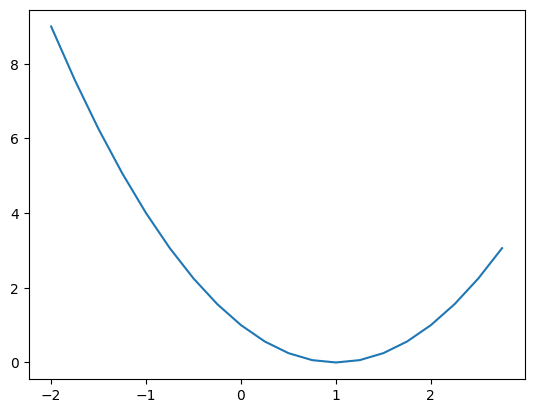

In [8]:
import numpy as np
import matplotlib.pyplot as plt
x = np.arange(-2, 3, 0.25)
y = x**2 - 2*x + 1
plt.plot(x, y)
plt.show()

#### Разбор кода

`plt.plot(x, y)` использует пары `(x[i], y[i])`. Соседние точки соединяются линиями. Для корректного построения массивы `x` и `y` должны содержать согласованные пары данных.

### Пример 9. `scatter` и `stem`

**Задача.** Показать один набор дискретных данных как отдельные точки и как стеблевую диаграмму.

**Понятия, уже использованные в работе:** `python_list`, `len`, `indexing`, `negative_index`, `slice`, `range`, `for_loop`, `list_append`, `list_comprehension`, `numpy_array`, `shape`, `numpy_arange`, `vectorized_expression`, `plot`.

**Новые понятия:** `scatter`, `stem`.

#### Новые понятия

- `scatter` — Отображение набора отдельных точек без соединяющих линий.
- `stem` — Стеблевое представление дискретных отсчётов.

#### Математическая модель

Исходные данные — конечный набор пар
$$(x_i,y_i),\quad i=0,1,\ldots,N-1.$$

#### Числовой пример

Для $x=[0,1,2]$, $y=[1,3,2]$ имеются три отдельных наблюдения: $(0,1)$, $(1,3)$, $(2,2)$.

#### Объяснение

`scatter` подчёркивает отдельные наблюдения, а `stem` — значения дискретных отсчётов относительно базовой линии. Числовые данные в обоих случаях одинаковы.

#### Код решения

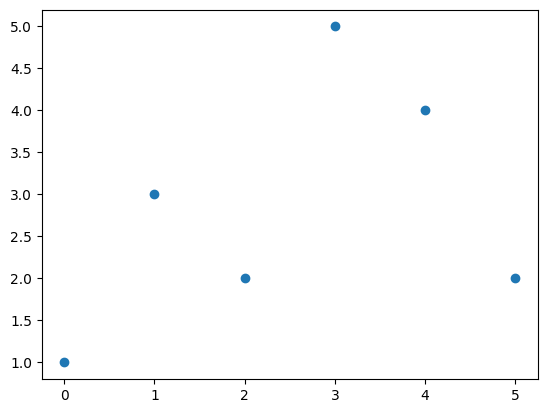

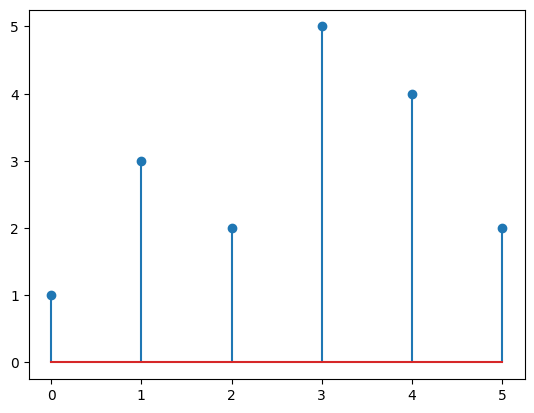

In [9]:
import numpy as np
import matplotlib.pyplot as plt
x = np.arange(0, 6)
y = np.array([1, 3, 2, 5, 4, 2])
plt.scatter(x, y)
plt.show()
plt.stem(x, y)
plt.show()

#### Разбор кода

Первый рисунок отображает только точки наблюдений. Второй дополнительно проводит вертикальные отрезки к базовой линии и поэтому хорошо подчёркивает дискретность отсчётов.

### Пример 10. `step` и `bar`

**Задача.** Отобразить одни данные ступенями и столбцами и объяснить, какие свойства представления меняются.

**Понятия, уже использованные в работе:** `python_list`, `len`, `indexing`, `negative_index`, `slice`, `range`, `for_loop`, `list_append`, `list_comprehension`, `numpy_array`, `shape`, `numpy_arange`, `vectorized_expression`, `plot`, `scatter`, `stem`.

**Новые понятия:** `step`, `bar`.

#### Новые понятия

- `step` — Ступенчатое отображение последовательности данных.
- `bar` — Столбчатая диаграмма; не гистограмма распределения.

#### Математическая модель

Числовые пары остаются теми же:
$$(x_i,y_i).$$
Меняется правило визуального представления между или около этих точек.

#### Числовой пример

Для $x=[0,1,2]$, $y=[2,4,1]$ `step` показывает уровни, а `bar` — три отдельные величины столбцами.

#### Объяснение

`step` полезен, когда значение интерпретируется как уровень между соседними отсчётами. `bar` удобен для сравнения отдельных величин. Столбчатая диаграмма не является гистограммой распределения.

#### Код решения

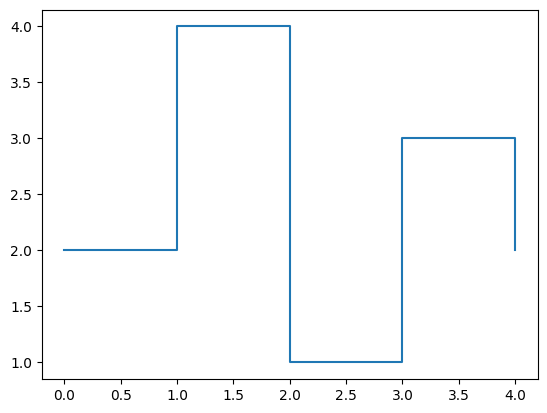

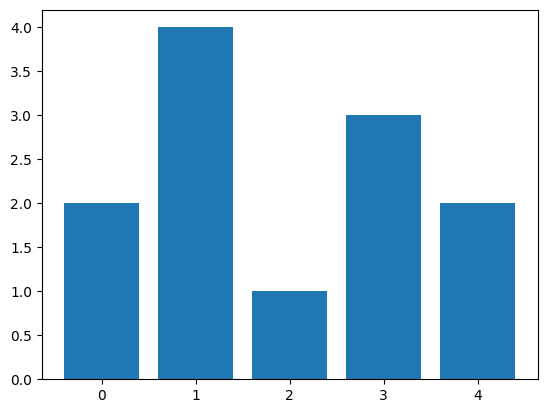

In [10]:
import numpy as np
import matplotlib.pyplot as plt
x = np.arange(0, 5)
y = np.array([2, 4, 1, 3, 2])
plt.step(x, y, where='post')
plt.show()
plt.bar(x, y)
plt.show()

#### Разбор кода

`step` интерпретирует значение как уровень, сохраняющийся на некотором интервале; параметр `where='post'` задаёт момент перехода. `bar` представляет каждое значение отдельным столбцом. Это разные способы отображения, а не разные исходные данные.

**Итог раздела.** Один набор чисел можно отображать по-разному. Выбор между линией, точками, стеблями, ступенями и столбцами определяется смыслом данных, а не только внешним видом рисунка.

# 5. Оформление и сравнение графиков

После построения данных график должен быть читаемым: оси и серии следует подписать, при необходимости добавить сетку и разумно выбрать окно отображения.

### Пример 11. Подписи, заголовок и сетка

**Задача.** Оформить график так, чтобы его можно было интерпретировать без обращения к коду.

**Понятия, уже использованные в работе:** `python_list`, `len`, `indexing`, `negative_index`, `slice`, `range`, `for_loop`, `list_append`, `list_comprehension`, `numpy_array`, `shape`, `numpy_arange`, `vectorized_expression`, `plot`, `scatter`, `stem`, `step`, `bar`.

**Новые понятия:** `axis_labels`, `title`, `grid`.

#### Новые понятия

- `axis_labels` — Подписи осей графика.
- `title` — Заголовок графика.
- `grid` — Координатная сетка на графике.

#### Математическая модель

Для зависимости
$$y_i=x_i^2$$
подписи должны однозначно указывать, что отложено по каждой оси.

#### Числовой пример

Если $x=2$, то $y=4$; сетка облегчает считывание такой пары координат с рисунка.

#### Объяснение

Подписи осей описывают физический или математический смысл координат. Заголовок кратко обозначает содержание рисунка. Сетка помогает визуально сопоставлять положение точки с делениями осей.

#### Код решения

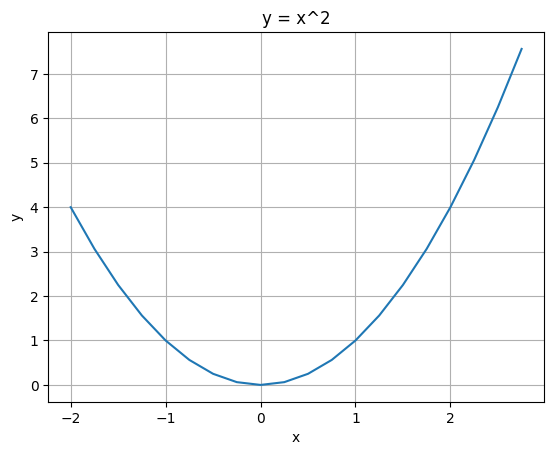

In [11]:
import numpy as np
import matplotlib.pyplot as plt
x = np.arange(-2, 3, 0.25)
y = x**2
plt.plot(x, y)
plt.xlabel('x')
plt.ylabel('y')
plt.title('y = x^2')
plt.grid(True)
plt.show()

#### Разбор кода

После построения зависимости команды `xlabel` и `ylabel` задают смысл координатных осей, `title` — название рисунка, `grid(True)` — сетку. Они меняют оформление, а не числовые массивы.

### Пример 12. Пределы осей

**Задача.** Показать только центральный участок графика и проверить, что исходные данные при этом сохранились.

**Понятия, уже использованные в работе:** `python_list`, `len`, `indexing`, `negative_index`, `slice`, `range`, `for_loop`, `list_append`, `list_comprehension`, `numpy_array`, `shape`, `numpy_arange`, `vectorized_expression`, `plot`, `scatter`, `stem`, `step`, `bar`, `axis_labels`, `title`, `grid`.

**Новые понятия:** `axis_limits`.

#### Новые понятия

- `axis_limits` — Явное задание отображаемого диапазона осей.

#### Математическая модель

Массивы $(x_i,y_i)$ не изменяются. Задаётся только окно отображения
$$x_{min}\le x\le x_{max},\qquad y_{min}\le y\le y_{max}.$$

#### Числовой пример

Если массив содержит $x$ от $-5$ до $5$, можно показать только участок $-2\le x\le2$, не удаляя остальные элементы.

#### Объяснение

Пределы осей относятся к визуализации, а не к самим данным. Это важно при анализе: «не видно на рисунке» не означает «отсутствует в массиве».

#### Код решения

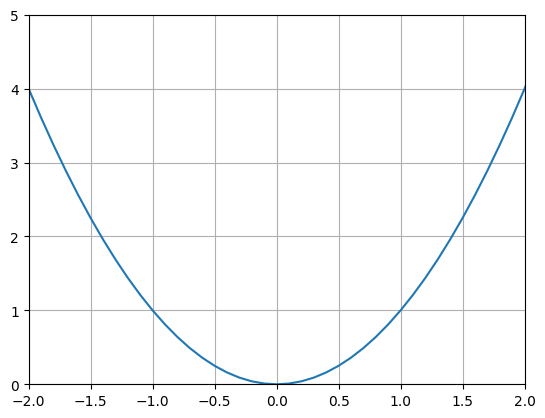

data x-range: -5.0 4.9999999999999645
data y max: 25.0


In [12]:
import numpy as np
import matplotlib.pyplot as plt
x = np.arange(-5, 5.1, 0.1)
y = x**2
plt.plot(x, y)
plt.xlim(-2, 2)
plt.ylim(0, 5)
plt.grid(True)
plt.show()
print('data x-range:', x.min(), x.max())
print('data y max:', y.max())

#### Разбор кода

Команды `xlim` и `ylim` ограничивают видимое окно. Вывод min/max после рисунка показывает, что исходные значения не были обрезаны или пересчитаны.

### Пример 13. Несколько зависимостей и легенда

**Задача.** Построить $y=x$ и $y=x^2$ на одних осях и различить их с помощью легенды.

**Понятия, уже использованные в работе:** `python_list`, `len`, `indexing`, `negative_index`, `slice`, `range`, `for_loop`, `list_append`, `list_comprehension`, `numpy_array`, `shape`, `numpy_arange`, `vectorized_expression`, `plot`, `scatter`, `stem`, `step`, `bar`, `axis_labels`, `title`, `grid`, `axis_limits`.

**Новые понятия:** `multiple_series`, `legend`.

#### Новые понятия

- `multiple_series` — Отображение нескольких зависимостей на одних координатных осях.
- `legend` — Легенда для различения нескольких зависимостей.

#### Математическая модель

Для каждого $x_i$ вычисляются две величины:
$$y_{1,i}=x_i,\qquad y_{2,i}=x_i^2.$$

#### Числовой пример

При $x=2$ получаем $y_1=2$ и $y_2=4$; при $x=1$ обе величины равны 1.

#### Объяснение

Несколько серий удобно сравнивать на общих осях. Каждой серии задаётся подпись `label`; `legend()` выводит эти подписи и делает рисунок самодостаточным.

#### Код решения

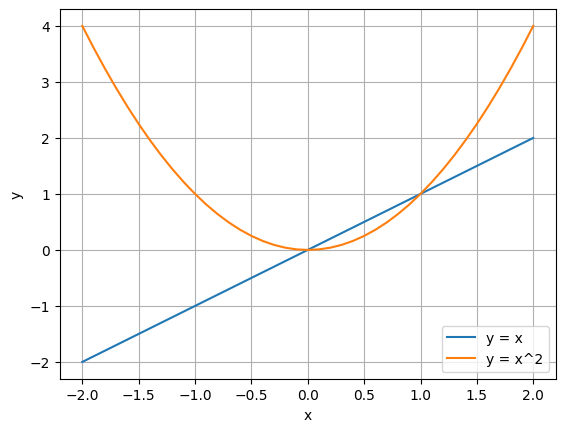

In [13]:
import numpy as np
import matplotlib.pyplot as plt
x = np.arange(-2, 2.1, 0.1)
y1 = x
y2 = x**2
plt.plot(x, y1, label='y = x')
plt.plot(x, y2, label='y = x^2')
plt.xlabel('x')
plt.ylabel('y')
plt.grid(True)
plt.legend()
plt.show()

#### Разбор кода

Два вызова `plot` рисуют две серии на одних осях. Аргумент `label` связывает текст с серией, а `legend()` выводит соответствия на рисунке.

**Итог раздела.** Оформление не заменяет данные, но делает их интерпретацию корректной. Несколько зависимостей можно сравнивать на общих осях, если серии явно различены.

# 6. Табличный, числовой и визуальный анализ

График даёт быстрый общий взгляд, но точные значения следует получать из массива. Поэтому визуальный анализ дополняется вычислением характеристик и табличным представлением.

### Пример 14. Минимум, максимум и индекс

**Задача.** Найти минимальное и максимальное значения массива, а также значение аргумента, которому соответствует максимум.

**Понятия, уже использованные в работе:** `python_list`, `len`, `indexing`, `negative_index`, `slice`, `range`, `for_loop`, `list_append`, `list_comprehension`, `numpy_array`, `shape`, `numpy_arange`, `vectorized_expression`, `plot`, `scatter`, `stem`, `step`, `bar`, `axis_labels`, `title`, `grid`, `axis_limits`, `multiple_series`, `legend`.

**Новые понятия:** `min_max`, `argmax`.

#### Новые понятия

- `min_max` — Определение минимального и максимального значений массива.
- `argmax` — Определение индекса максимального элемента массива.

#### Математическая модель

Для массива $y$ определяются
$$y_{min}=\min_i y_i,\qquad y_{max}=\max_i y_i.$$
Если $k$ — индекс максимума, то соответствующий аргумент равен $x_k$.

#### Числовой пример

Для $y=[4,1,0,1,4]$ максимум равен 4. Один из его индексов — 0; соответствующий элемент массива $x$ берётся как $x_0$.

#### Объяснение

`np.argmax` возвращает индекс первого найденного максимума. Индекс связывает разные массивы: если `x[i]` и `y[i]` образуют одну точку, то найденный индекс позволяет перейти от экстремума `y` к соответствующему `x`.

#### Код решения

In [14]:
import numpy as np
x = np.arange(-2, 3, 1)
y = np.array([4, 1, 0, 1, 4])
i = np.argmax(y)
print('min =', np.min(y))
print('max =', np.max(y))
print('index max =', i)
print('x at max =', x[i])

min = 0
max = 4
index max = 0
x at max = -2


#### Разбор кода

`np.min` и `np.max` возвращают значения экстремумов. `np.argmax(y)` возвращает индекс максимального элемента. Тот же индекс можно использовать для массива `x`, чтобы получить значение аргумента, которому соответствует максимум `y`.

### Пример 15. Сумма, среднее и таблица

**Задача.** Вычислить сумму и среднее значений и вывести пары $(x_i,y_i)$ в виде таблицы.

**Понятия, уже использованные в работе:** `python_list`, `len`, `indexing`, `negative_index`, `slice`, `range`, `for_loop`, `list_append`, `list_comprehension`, `numpy_array`, `shape`, `numpy_arange`, `vectorized_expression`, `plot`, `scatter`, `stem`, `step`, `bar`, `axis_labels`, `title`, `grid`, `axis_limits`, `multiple_series`, `legend`, `min_max`, `argmax`.

**Новые понятия:** `sum`, `mean`, `formatted_table`.

#### Новые понятия

- `sum` — Сумма элементов числового массива.
- `mean` — Среднее арифметическое элементов массива.
- `formatted_table` — Табличный вывод связанных значений с управлением шириной и точностью полей.

#### Математическая модель

Сумма и среднее определяются как
$$S=\sum_{i=0}^{N-1}y_i,\qquad \mu=\frac{S}{N}.$$

#### Числовой пример

Для $y=[2,4,3,5,1]$ имеем $S=15$ и $\mu=3$.

#### Объяснение

Числовые характеристики удобно сопровождать таблицей. Форматированная строка позволяет выровнять столбцы и ограничить число знаков после десятичной точки.

#### Код решения

In [15]:
import numpy as np
x = np.arange(0, 5)
y = np.array([2, 4, 3, 5, 1])
print('sum =', np.sum(y))
print('mean =', np.mean(y))
print('   x      y')
for i in range(len(x)):
    print(f'{x[i]:4.0f} {y[i]:6.1f}')

sum = 15
mean = 3.0
   x      y
   0    2.0
   1    4.0
   2    3.0
   3    5.0
   4    1.0


#### Разбор кода

`np.sum(y)` вычисляет сумму, `np.mean(y)` — среднее. Цикл проходит по общим индексам массивов `x` и `y`; f-строка задаёт ширину и число знаков в столбцах таблицы.

### Пример 16. Сопоставление графика и данных

**Задача.** По графику оценить положение минимума, затем определить его по массивам и сравнить результаты.

**Понятия, уже использованные в работе:** `python_list`, `len`, `indexing`, `negative_index`, `slice`, `range`, `for_loop`, `list_append`, `list_comprehension`, `numpy_array`, `shape`, `numpy_arange`, `vectorized_expression`, `plot`, `scatter`, `stem`, `step`, `bar`, `axis_labels`, `title`, `grid`, `axis_limits`, `multiple_series`, `legend`, `min_max`, `argmax`, `sum`, `mean`, `formatted_table`.

**Новые понятия:** `visual_analysis`.

#### Новые понятия

- `visual_analysis` — Получение простых выводов по графику и сопоставление графика с числовыми данными.

#### Математическая модель

Рассматривается зависимость
$$y_i=(x_i-1)^2.$$
Минимум массива $y$ находится там же, где максимум массива $-y$.

#### Числовой пример

При $x=1$ получаем $y=0$, поэтому ожидается минимум около точки $(1,0)$.

#### Объяснение

Сначала формулируется визуальное предположение, затем оно проверяется численно. Такой порядок полезен: график показывает структуру зависимости, а массив даёт точное значение в выбранной дискретной сетке.

#### Код решения

minimum y = 1.9721522630525295e-31
x at minimum = 0.9999999999999996


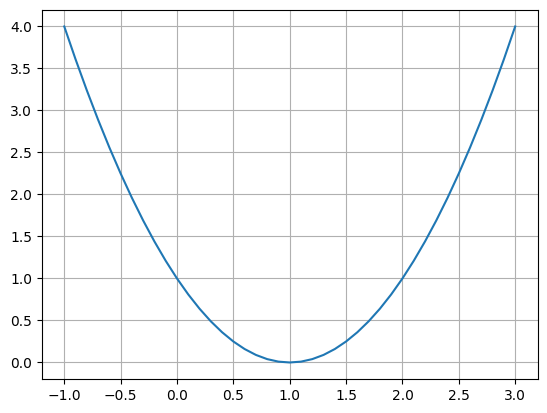

In [16]:
import numpy as np
import matplotlib.pyplot as plt
x = np.arange(-1, 3.1, 0.1)
y = (x - 1)**2
i = np.argmax(-y)
print('minimum y =', y[i])
print('x at minimum =', x[i])
plt.plot(x, y)
plt.grid(True)
plt.show()

#### Разбор кода

Сначала минимум определяется численно: максимум массива `-y` находится в том же месте, что минимум `y`. Затем график используется как независимая визуальная проверка результата. Это связывает числовое и графическое представления.

### Пример 17. Чтение и отладка кода

**Задача.** Проверить готовый код построения $y=2x+1$: сначала объяснить результат, затем убедиться в согласованности данных.

**Понятия, уже использованные в работе:** `python_list`, `len`, `indexing`, `negative_index`, `slice`, `range`, `for_loop`, `list_append`, `list_comprehension`, `numpy_array`, `shape`, `numpy_arange`, `vectorized_expression`, `plot`, `scatter`, `stem`, `step`, `bar`, `axis_labels`, `title`, `grid`, `axis_limits`, `multiple_series`, `legend`, `min_max`, `argmax`, `sum`, `mean`, `formatted_table`, `visual_analysis`.

**Новые понятия:** `code_analysis`, `debugging`.

#### Новые понятия

- `code_analysis` — Предсказание результата и объяснение готового кода без запуска.
- `debugging` — Поиск и исправление смысловой или программной ошибки в готовом решении.

#### Математическая модель

Для каждой пары должен выполняться закон
$$y_i=2x_i+1,$$
и число значений должно совпадать:
$$N_x=N_y.$$

#### Числовой пример

Если $x=[0,1,2]$, то правильный массив $y=[1,3,5]$ и обе последовательности имеют длину 3.

#### Объяснение

При анализе готового решения полезно идти в порядке «математическое правило → массивы → визуализация». Проверка длины не доказывает правильность формулы, но обнаруживает распространённый класс ошибок с несогласованными данными.

#### Код решения

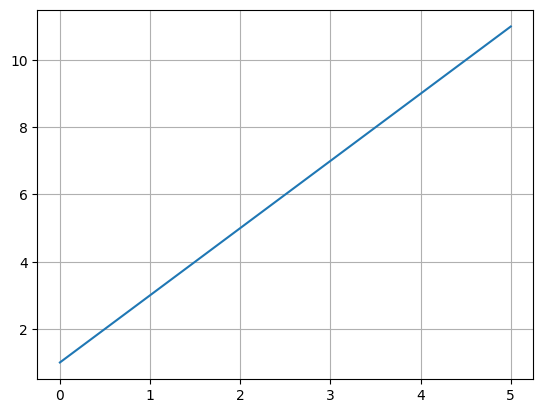

In [17]:
import numpy as np
import matplotlib.pyplot as plt
x = np.arange(0, 6)
y = 2*x + 1
assert len(x) == len(y)
plt.plot(x, y)
plt.grid(True)
plt.show()

#### Разбор кода

При отладке сначала проверяется математическая формула, затем структура данных. `assert len(x) == len(y)` фиксирует важное условие: каждому x должно соответствовать одно y. После этого строится график.

**Итог раздела.** Числовые характеристики и таблица дают точные значения, график показывает общую форму, а анализ кода позволяет проверить, каким способом эти данные были получены.

# 7. Три семейства функций, особые точки и логарифмический масштаб

Для последующих самостоятельных и контрольных заданий будем использовать три одинаковых семейства функций. Во всех вариантах меняются только коэффициенты:

$$P(x)=ax^2+bx+c,$$

$$R(x)=\frac{px+q}{x-d},$$

$$T(x)=A\sin(\omega x+\varphi)+B\cos(kx).$$

Такая схема позволяет сравнивать решения разных вариантов: алгоритм остаётся общим, а численные результаты отличаются.

### Пример 18. Полиномиальная и рациональная функции

**Задача.** Вычислить на одной сетке значения полинома и рациональной функции и сравнить их формулы с векторными выражениями NumPy.

**Понятия, уже использованные в работе:** `python_list`, `len`, `indexing`, `negative_index`, `slice`, `range`, `for_loop`, `list_append`, `list_comprehension`, `numpy_array`, `shape`, `numpy_arange`, `vectorized_expression`, `plot`, `scatter`, `stem`, `step`, `bar`, `axis_labels`, `title`, `grid`, `axis_limits`, `multiple_series`, `legend`, `min_max`, `argmax`, `sum`, `mean`, `formatted_table`, `visual_analysis`, `code_analysis`, `debugging`.

**Новые понятия:** `polynomial_function`, `rational_function`.

#### Новые понятия

- `polynomial_function` — функция, составленная из степеней $x$ с числовыми коэффициентами.
- `rational_function` — отношение двух полиномов; функция может быть не определена в точках, где знаменатель равен нулю.

#### Математическая модель

Рассмотрим
$$P(x)=x^2-x-2,$$

$$R(x)=\frac{x+1}{x-1}.$$

#### Числовой пример

При $x=0$: $P(0)=-2$, $R(0)=-1$. При $x=1$ знаменатель $R(x)$ равен нулю, поэтому значение функции не определено.

#### Код решения

In [18]:
import numpy as np
x = np.arange(-2, 2.1, 0.5)
p = x**2 - x - 2
# Пока исключим точку x=1 из вычисления рациональной функции.
r = np.full(x.shape, np.nan, dtype=float)
mask = x != 1
r[mask] = (x[mask] + 1) / (x[mask] - 1)
print('x =', x)
print('P =', p)
print('R =', r)

x = [-2.  -1.5 -1.  -0.5  0.   0.5  1.   1.5  2. ]
P = [ 4.    1.75  0.   -1.25 -2.   -2.25 -2.   -1.25  0.  ]
R = [ 0.33333333  0.2        -0.         -0.33333333 -1.         -3.
         nan  5.          3.        ]


#### Разбор кода

Полином вычисляется одной векторной формулой. Для рациональной функции сначала создаётся массив результата, затем отдельно обрабатываются точки, где знаменатель не равен нулю. Значение `nan` отмечает отсутствующее числовое значение и не должно интерпретироваться как обычное число.

### Пример 19. Тригонометрическая функция

**Задача.** Вычислить и построить комбинацию синуса и косинуса.

**Понятия, уже использованные в работе:** `python_list`, `len`, `indexing`, `negative_index`, `slice`, `range`, `for_loop`, `list_append`, `list_comprehension`, `numpy_array`, `shape`, `numpy_arange`, `vectorized_expression`, `plot`, `scatter`, `stem`, `step`, `bar`, `axis_labels`, `title`, `grid`, `axis_limits`, `multiple_series`, `legend`, `min_max`, `argmax`, `sum`, `mean`, `formatted_table`, `visual_analysis`, `code_analysis`, `debugging`, `polynomial_function`, `rational_function`.

**Новые понятия:** `trigonometric_function`, `numpy_trigonometry`.

#### Новые понятия

- `trigonometric_function` — функция, в формуле которой используются синус, косинус или другие тригонометрические функции.
- `numpy_trigonometry` — поэлементное вычисление `np.sin`, `np.cos` и других функций NumPy для массива аргументов.

#### Математическая модель

$$T(x)=2\sin(x)+\cos(2x).$$

#### Числовой пример

При $x=0$: $T(0)=2\cdot0+1=1$.

#### Код решения

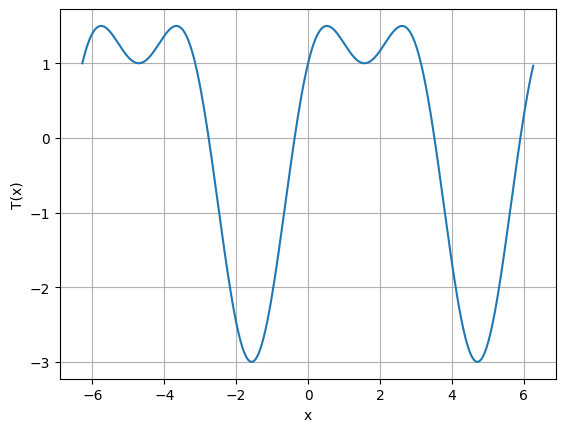

In [19]:
import numpy as np
import matplotlib.pyplot as plt
x = np.arange(-2*np.pi, 2*np.pi, 0.05)
t = 2*np.sin(x) + np.cos(2*x)
plt.plot(x, t)
plt.xlabel('x')
plt.ylabel('T(x)')
plt.grid(True)
plt.show()

#### Разбор кода

`np.sin(x)` и `np.cos(2*x)` возвращают массивы той же формы, что и `x`. Поэтому комбинация функций вычисляется без явного цикла.

### Пример 20. Неопределённая точка и разрыв графика

**Задача.** Для рациональной функции явно исключить точку, где знаменатель равен нулю, и не соединять левую и правую части графика через эту точку.

**Понятия, уже использованные в работе:** `python_list`, `len`, `indexing`, `negative_index`, `slice`, `range`, `for_loop`, `list_append`, `list_comprehension`, `numpy_array`, `shape`, `numpy_arange`, `vectorized_expression`, `plot`, `scatter`, `stem`, `step`, `bar`, `axis_labels`, `title`, `grid`, `axis_limits`, `multiple_series`, `legend`, `min_max`, `argmax`, `sum`, `mean`, `formatted_table`, `visual_analysis`, `code_analysis`, `debugging`, `polynomial_function`, `rational_function`, `trigonometric_function`, `numpy_trigonometry`.

**Новые понятия:** `boolean_mask`, `nan_value`, `discontinuity`.

#### Новые понятия

- `boolean_mask` — массив значений `True/False`, выбирающий элементы, удовлетворяющие условию.
- `nan_value` — специальное значение `np.nan`, обозначающее отсутствующее или неопределённое числовое значение.
- `discontinuity` — точка разрыва: значение функции отсутствует или поведение слева и справа не образует обычной непрерывной кривой.

#### Математическая модель

$$R(x)=\frac{x+1}{x-1},\qquad x\ne1.$$

#### Числовой пример

Для $x=0.5$ получаем $R=-3$, для $x=1.5$ получаем $R=5$, а при $x=1$ значение отсутствует.

#### Код решения

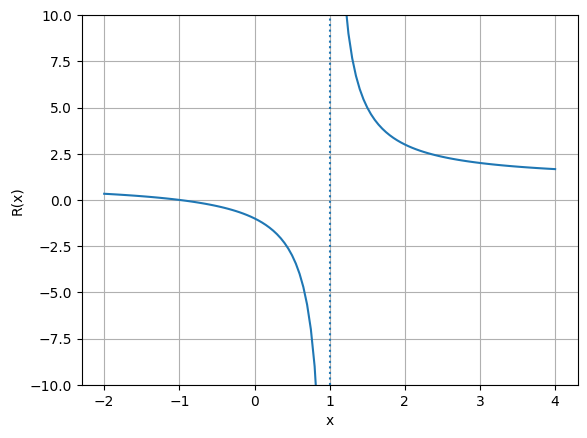

In [20]:
import numpy as np
import matplotlib.pyplot as plt
x = np.arange(-2, 4.01, 0.05)
r = np.full(x.shape, np.nan, dtype=float)
mask = np.abs(x - 1) > 1e-12
r[mask] = (x[mask] + 1) / (x[mask] - 1)
plt.plot(x, r)
plt.axvline(1, linestyle=':')
plt.xlabel('x')
plt.ylabel('R(x)')
plt.grid(True)
plt.ylim(-10, 10)
plt.show()

#### Разбор кода

Условие создаёт булеву маску допустимых точек. Значение в точке $x=1$ остаётся `np.nan`; `matplotlib` разрывает линию в таком месте. Явные пределы по оси $y$ не изменяют данные, а только делают поведение около разрыва читаемым.

### Пример 21. Обычный и логарифмический масштаб

**Задача.** Сравнить обычный и логарифмический масштаб для положительной функции, значения которой различаются на несколько порядков.

**Понятия, уже использованные в работе:** `python_list`, `len`, `indexing`, `negative_index`, `slice`, `range`, `for_loop`, `list_append`, `list_comprehension`, `numpy_array`, `shape`, `numpy_arange`, `vectorized_expression`, `plot`, `scatter`, `stem`, `step`, `bar`, `axis_labels`, `title`, `grid`, `axis_limits`, `multiple_series`, `legend`, `min_max`, `argmax`, `sum`, `mean`, `formatted_table`, `visual_analysis`, `code_analysis`, `debugging`, `polynomial_function`, `rational_function`, `trigonometric_function`, `numpy_trigonometry`, `boolean_mask`, `nan_value`, `discontinuity`.

**Новые понятия:** `dynamic_range`, `log_scale`.

#### Новые понятия

- `dynamic_range` — отношение или размах между малыми и большими значениями величины; при различии на много порядков обычный масштаб может скрывать малые значения.
- `log_scale` — логарифмический масштаб оси, в котором равные расстояния соответствуют равным отношениям значений, а не равным разностям.

#### Математическая модель

Рассмотрим положительную функцию
$$G(x)=(x+1)^8,\qquad x\ge0.$$

#### Числовой пример

$G(0)=1$, $G(1)=256$, $G(9)=10^8$. Значения различаются на восемь порядков, поэтому логарифмический масштаб позволяет одновременно видеть малые и большие значения.

#### Код решения

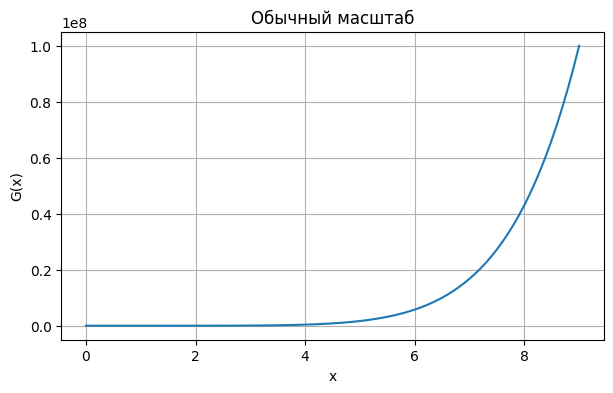

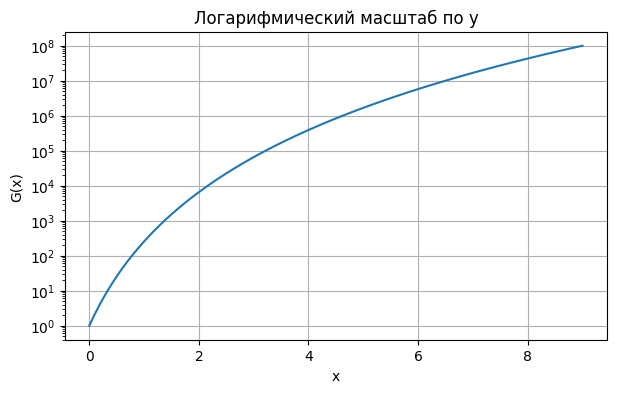

In [21]:
import numpy as np
import matplotlib.pyplot as plt
x = np.arange(0, 9.01, 0.1)
g = (x + 1)**8

plt.figure(figsize=(7, 4))
plt.plot(x, g)
plt.xlabel('x')
plt.ylabel('G(x)')
plt.title('Обычный масштаб')
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(x, g)
plt.yscale('log')
plt.xlabel('x')
plt.ylabel('G(x)')
plt.title('Логарифмический масштаб по y')
plt.grid(True)
plt.show()

#### Разбор кода

Массив данных в обоих рисунках один и тот же. Команда `plt.yscale('log')` изменяет только способ отображения оси. Для обычной логарифмической шкалы по $y$ рассматривают положительные значения; разрыв рациональной функции сам по себе не является причиной перехода к логарифмическому масштабу.

**Итог раздела.** Для вариантов работы далее используются три семейства $P(x)$, $R(x)$ и $T(x)$. Рациональная функция даёт естественный пример неопределённой точки и разрыва; логарифмический масштаб вводится отдельно для положительных данных с большим динамическим диапазоном.

# 8. Самостоятельная работа

Для каждого задания предусмотрено 25 вариантов в отдельном файле `lab01_1d_arrays_graphs_variants_v6.py`. Студент использует один и тот же номер варианта во всех назначенных заданиях.

Полный разбор решения здесь не приводится. Самостоятельные задания используют наиболее производные понятия соответствующих разделов; необходимые базовые операции применяются по необходимости.

## Задание С1. Индексы и срезы

Для списка своего варианта определите длину, указанные элементы, заданный срез и элементы с указанным шагом. Сначала запишите ожидаемый результат, затем проверьте его в Python.

## Задание С2. Генерация по формуле

На целочисленной сетке своего варианта сформируйте значения полинома $P(x)$ двумя способами: циклом с `append` и списочным выражением. Сравните результаты.

## Задание С3. Векторное вычисление NumPy

Создайте NumPy-сетку своего варианта с дробным шагом и вычислите $P(x)$ одной векторной формулой. Выведите `shape` массивов и сравните несколько значений с ручным расчётом.

## Задание С4. Выбор способа визуализации

Для набора дискретных данных своего варианта выберите два способа отображения из `plot`, `scatter`, `stem`, `step`, `bar`. Объясните, какую особенность данных подчёркивает каждый способ.

## Задание С5. Оформление и сравнение

На общих осях постройте $P(x)$ и $T(x)$ своего варианта. Добавьте подписи осей, заголовок, сетку, легенду и разумные пределы осей.

## Задание С6. Числовой и визуальный анализ

Для $P(x)$ своего варианта выведите таблицу значений, найдите минимум, максимум, сумму, среднее и положение максимума. Постройте график и сопоставьте числовые результаты с его формой.

## Задание С7. Три семейства функций и масштаб

Для $P(x)$, $R(x)$ и $T(x)$ своего варианта:
1. вычислите массивы на заданной сетке;
2. корректно обработайте точку $x=d$ рациональной функции;
3. постройте три графика;
4. укажите, является ли особая точка $R(x)$ полюсом или устранимым разрывом;
5. отдельно постройте функцию $G(x)$ своего варианта в обычном и логарифмическом масштабе и сравните представления.

## Интегральное задание И1

Выполните полный анализ трёх функций $P(x)$, $R(x)$ и $T(x)$ своего варианта: сформируйте массивы, выведите выбранные числовые характеристики и таблицу, постройте оформленные графики и сделайте краткие выводы о форме функций и особых точках.

## Интегральное задание И2

Для функций своего варианта подготовьте программу сравнения $P(x)$ и $T(x)$ и построения $R(x)$. В копию программы внесите указанную в варианте ошибку, затем обнаружьте её по коду, численным данным или графику, исправьте и объясните порядок проверки.

# 9. Контрольные задания

Для каждого контрольного задания также подготовлено 25 вариантов в файле вариантов. Конкретный набор заданий для контроля выбирает преподаватель.

## К1. Индексы и срезы без запуска кода
Предскажите значения выражений с индексами и срезами для списка своего варианта и объясните результат.

## К2. Исправление `range`
Исправьте вызов `range`, чтобы последовательность включала указанное последнее значение при заданном направлении и шаге.

## К3. Цикл и списочное выражение
Получите значения $P(x)$ циклом и списочным выражением; объясните, почему результаты должны совпадать.

## К4. Три способа вычисления
Получите $P(x)$ циклом, списочным выражением и векторной формулой NumPy. Сравните результаты и код.

## К5. Выбор типа графика
Для данных своего варианта выберите наиболее подходящий способ отображения и обоснуйте выбор.

## К6. Чтение графика и проверка по массиву
По графику функции своего варианта оцените характерные значения и участки изменения, затем проверьте выводы численно.

## К7. Пределы осей
Сравните два изображения одной функции с разными пределами осей. Определите, изменились ли данные или только способ их отображения.

## К8. Сравнение двух функций
Постройте $P(x)$ и $T(x)$ своего варианта на одних осях и оцените точки их пересечения по дискретной сетке.

## К9. Таблица и график
По формуле и сетке своего варианта сформируйте таблицу пар $(x_i,y_i)$, постройте график и проверьте максимум и среднее.

## К10. Отладка согласованности массивов
Найдите причину ошибки в готовом фрагменте, где массивы `x` и `y` имеют разные длины, и исправьте генерацию данных.

## К11. Рациональная функция и особая точка
Для $R(x)$ своего варианта определите точку, где знаменатель равен нулю, корректно представьте отсутствующее значение в массиве и постройте график без ложного соединения через разрыв.

## К12. Логарифмический масштаб
Для положительной функции $G(x)$ своего варианта сравните обычный и логарифмический масштаб. Объясните, что изменилось на рисунке и что осталось неизменным в данных.

# Заключение

В работе была построена последовательная цепочка:

$$\text{последовательность чисел}\rightarrow\text{генерация}\rightarrow\text{NumPy-массив}\rightarrow\text{график}\rightarrow\text{анализ}.$$

Одномерный массив используется как общее представление данных. Более поздние понятия опираются на ранние: индексирование связывает элементы массивов, генерация создаёт сетку аргумента, векторные операции формируют значения функций, а график и числовой анализ дают разные способы исследования одних и тех же данных.